In [1]:
#Célula de código para reiniciar tudo caso eu me afaste por muito tempo do notebook (depois Kernel> restar Kernel> restart and clear output)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/lncrnas_gencode.csv"
)

gc_df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/lncrnas_gc.csv"
)

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Ambiente funcionando!")

Ambiente funcionando!


In [3]:
df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/lncrnas_gencode.csv"
)

df.head()

,gene,transcrito,tamanho,biotipo
0,GAS5,GAS5-292,697,lncRNA
1,GAS5,GAS5-231,1071,lncRNA
2,GAS5,GAS5-293,741,lncRNA
3,GAS5,GAS5-280,774,lncRNA
4,GAS5,GAS5-255,735,lncRNA


In [4]:
#Qual gene possui mais isoformas?
isoformas = (
    df.groupby("gene")
      .size()
      .reset_index(name="n_isoformas")
      .sort_values(
          "n_isoformas",
          ascending=False
      )
)

isoformas

,gene,n_isoformas
4,PVT1,426
0,GAS5,177
2,MALAT1,72
5,XIST,33
3,NEAT1,16
1,HOTAIR,14


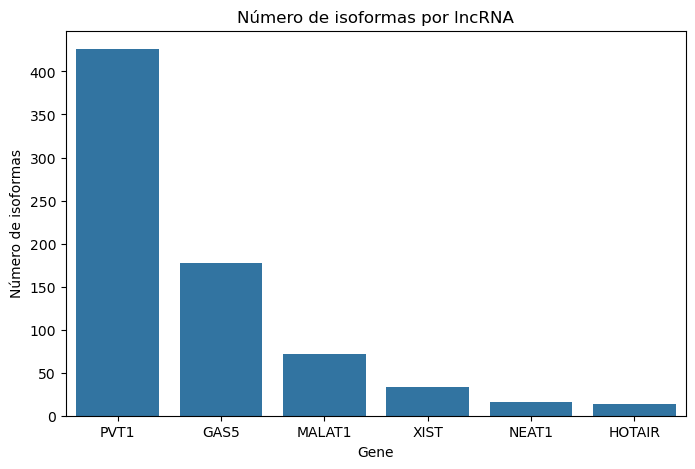

In [5]:
#Graficamente
plt.figure(figsize=(8,5))

sns.barplot(
    data=isoformas,
    x="gene",
    y="n_isoformas"
)

plt.title("Número de isoformas por lncRNA")
plt.xlabel("Gene")
plt.ylabel("Número de isoformas")

plt.show()

In [6]:
#Exercicio 2
df.sort_values(
    "tamanho",
    ascending=False
).head(10)

,gene,transcrito,tamanho,biotipo
603,NEAT1,NEAT1-202,23263,lncRNA
714,XIST,XIST-204,19245,lncRNA
708,XIST,XIST-225,13180,lncRNA
717,XIST,XIST-223,12555,lncRNA
619,MALAT1,MALAT1-202,10468,lncRNA
720,XIST,XIST-222,8258,lncRNA
723,XIST,XIST-218,8184,lncRNA
725,XIST,XIST-219,7717,lncRNA
660,MALAT1,MALAT1-228,6695,lncRNA
635,MALAT1,MALAT1-201,6168,lncRNA


In [7]:
estatisticas = (
    df.groupby("gene")["tamanho"]
      .agg([
          "count",
          "mean",
          "median",
          "min",
          "max"
      ])
)

estatisticas

,count,mean,median,min,max
gene,,,,,
GAS5,177,791.259887,633.0,322,3145
HOTAIR,14,1161.071429,1131.5,368,2415
MALAT1,72,2176.055556,1877.5,282,10468
NEAT1,16,3500.437500,1743.5,512,23263
PVT1,426,1179.640845,1132.5,283,2450
XIST,33,4226.939394,2867.0,583,19245


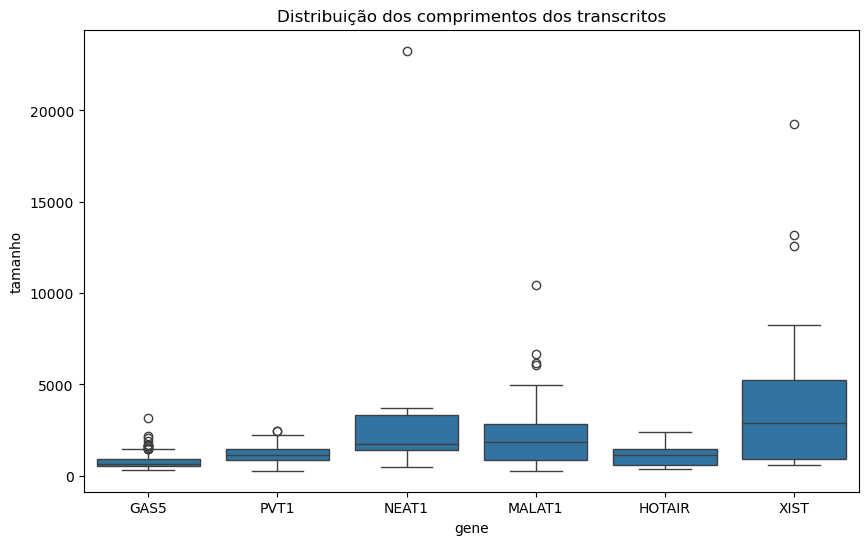

In [8]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="gene",
    y="tamanho"
)

plt.title("Distribuição dos comprimentos dos transcritos")
plt.show()

lncRNAs muito longos podem servir de plataformas ("scaffolds") para recrutamento simultâneo de múltiplas proteínas.
Essa hipótese aparece frequentemente na literatura de MALAT1, NEAT1 e XIST.

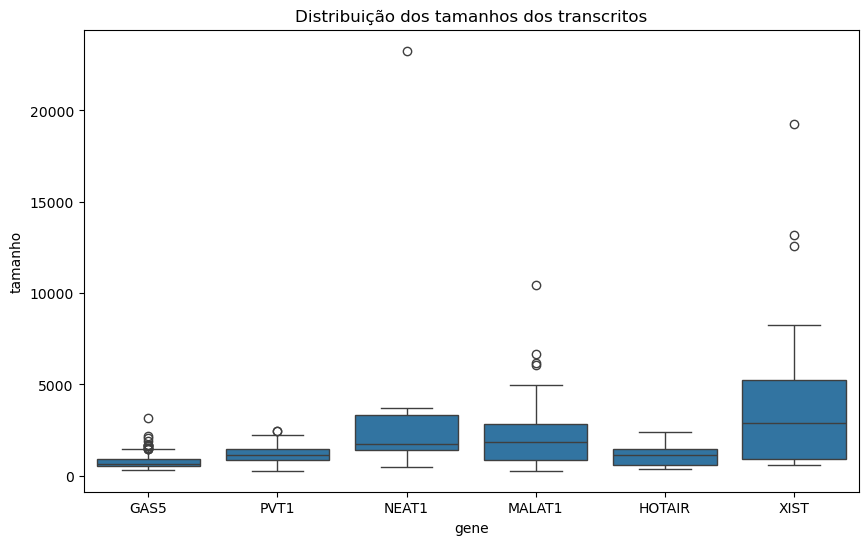

In [9]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="gene",
    y="tamanho"
)

plt.title("Distribuição dos tamanhos dos transcritos")
plt.show()

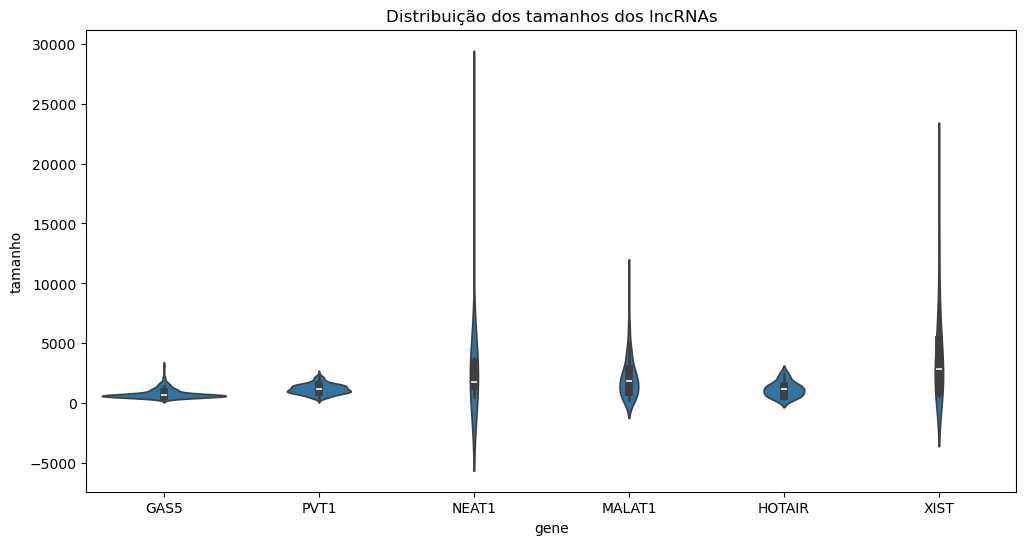

In [10]:
plt.figure(figsize=(12,6))

sns.violinplot(
    data=df,
    x="gene",
    y="tamanho"
)

plt.title("Distribuição dos tamanhos dos lncRNAs")
plt.show()

In [11]:
gc_df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/lncrnas_gc.csv"
)

gc_df.head()

,gene,transcrito,tamanho,gc
0,GAS5,GAS5-292,697,48.923960
1,GAS5,GAS5-231,1071,45.004669
2,GAS5,GAS5-293,741,46.153846
3,GAS5,GAS5-280,774,45.865633
4,GAS5,GAS5-255,735,44.353741


In [12]:
gc_df.groupby("gene")["gc"].mean().sort_values(
    ascending=False
)

gene
HOTAIR    50.784363
PVT1      50.656635
NEAT1     49.487199
GAS5      44.560798
XIST      41.814761
MALAT1    39.344824
Name: gc, dtype: float64

MALAT1 é relativamente longa e tem GC baixo.
XIST é enorme e GC moderado.
HOTAIR é muito menor e GC alto. Ou seja, comprimento e GC não parecem explicar um ao outro diretamente nesses lncRNAs.
Vamos medir

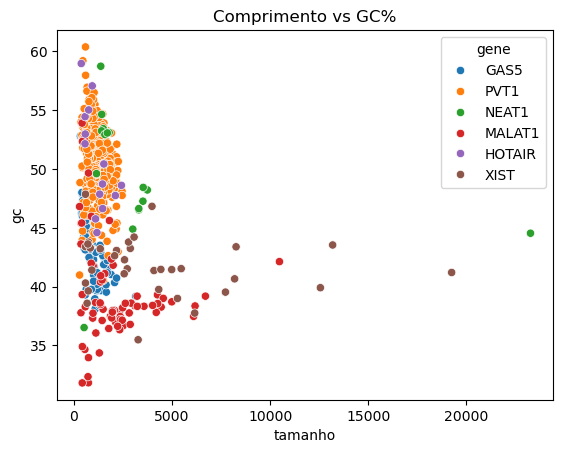

In [13]:
sns.scatterplot(
    data=gc_df,
    x="tamanho",
    y="gc",
    hue="gene"
)

plt.title("Comprimento vs GC%")
plt.show()

In [14]:
#Correlação entre tamanho vs. GC% (pq eu achei que maior tamanho precisaria de mais GC para manter a estabilidade da molécula, mas não é o caso)
gc_df["tamanho"].corr(gc_df["gc"])


np.float64(-0.24692076253732761)

O resultado indica uma correlação negativa moderada (np.float64(-0.24692076253732753)): o resultado da correlação foi moderadamente negativa np.float64(-0.24692076253732753) o que pode contradizer meu presuposto anterior, talvez estruturas maiores coexistam melhor estando relapsas e sua estabilidade conformacional e interação esteja associada a outros fatores com correlação mais forte. Asim, lncRNAs muito longos podem não depender predominantemente da estabilidade termodinâmica distribuída ao longo de toda a molécula. Em vez disso, podem depender de domínios estruturais específicos, proteínas associadas e organização espacial. Pois:
PVT1 → muitas isoformas + GC alto
HOTAIR → poucas isoformas + GC alto
NEAT1 → poucas isoformas + muito longo + GC alto
MALAT1 → intermediário em isoformas + GC relativamente baixo
Logo: provavelmente existem múltiplas estratégias evolutivas para lncRNAs funcionais.

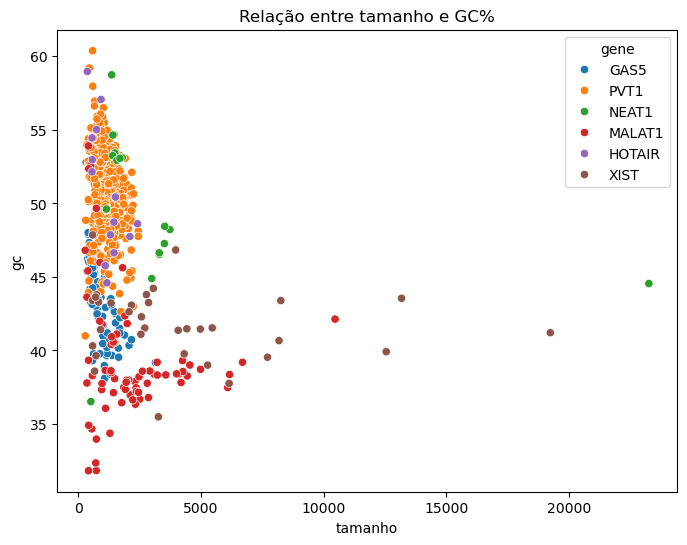

In [15]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=gc_df,
    x="tamanho",
    y="gc",
    hue="gene"
)

plt.title("Relação entre tamanho e GC%")
plt.show()

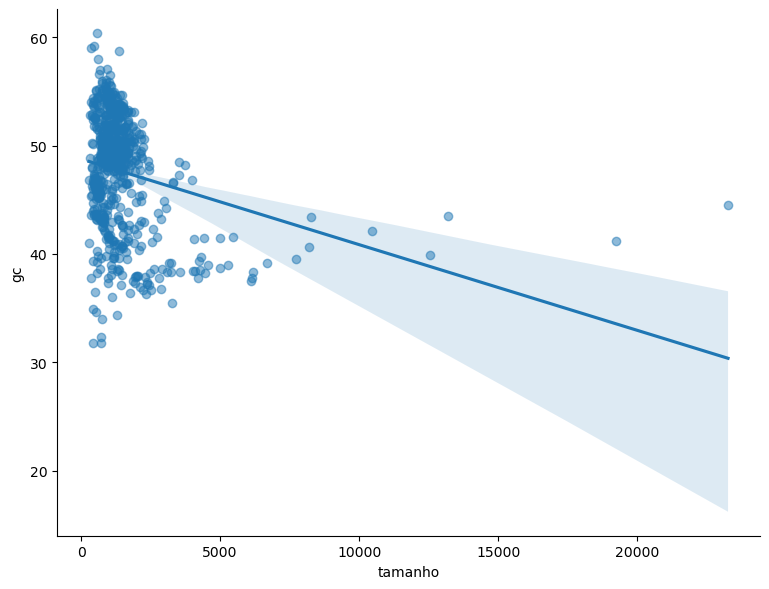

In [16]:
sns.lmplot(
    data=gc_df,
    x="tamanho",
    y="gc",
    scatter_kws={"alpha":0.5},
    height=6,
    aspect=1.3
)

Esses lncRNAs apresentam potencial diferente para interação molecular?
Para isso vamos verificar:
Frequência de dinucleotídeos.
Frequência de trinucleotídeos.
Maior ORF por transcrito.
Comprimento normalizado pela quantidade de isoformas.

Ordem metodológicamente correta:
1. Comprimento normalizado por isoformas
2. Maior ORF
3. Dinucleotídeos
4. Trinucleotídeos

In [17]:
import pandas as pd

df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/lncrnas_gencode.csv"
)

df.head()

,gene,transcrito,tamanho,biotipo
0,GAS5,GAS5-292,697,lncRNA
1,GAS5,GAS5-231,1071,lncRNA
2,GAS5,GAS5-293,741,lncRNA
3,GAS5,GAS5-280,774,lncRNA
4,GAS5,GAS5-255,735,lncRNA


In [18]:
resumo = (
    df.groupby("gene")
      .agg(
          n_isoformas=("transcrito", "count"),
          tamanho_medio=("tamanho", "mean"),
          tamanho_total=("tamanho", "sum")
      )
)

resumo["comprimento_por_isoforma"] = (
    resumo["tamanho_total"] /
    resumo["n_isoformas"]
)

resumo

,n_isoformas,tamanho_medio,tamanho_total,comprimento_por_isoforma
gene,,,,
GAS5,177,791.259887,140053,791.259887
HOTAIR,14,1161.071429,16255,1161.071429
MALAT1,72,2176.055556,156676,2176.055556
NEAT1,16,3500.437500,56007,3500.437500
PVT1,426,1179.640845,502527,1179.640845
XIST,33,4226.939394,139489,4226.939394


Esses lncRNAs diferem no potencial codificante residual?

In [19]:
orf_df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/orfs.csv"
)

orf_df.head()

,gene,transcrito,tamanho,maior_orf
0,GAS5,GAS5-292,697,153
1,GAS5,GAS5-231,1071,153
2,GAS5,GAS5-293,741,153
3,GAS5,GAS5-280,774,153
4,GAS5,GAS5-255,735,198


In [20]:
#estatisticas do maior ORF por gene
orf_df.groupby("gene")["maior_orf"].describe()

,count,mean,std,min,25%,50%,75%,max
gene,,,,,,,,
GAS5,177.0,201.728814,51.941126,102.0,153.0,198.0,198.00,333.0
HOTAIR,14.0,149.571429,83.610557,15.0,114.0,114.0,170.25,321.0
MALAT1,72.0,142.041667,43.334414,27.0,127.5,159.0,168.00,213.0
NEAT1,16.0,244.500000,75.243604,102.0,216.0,216.0,294.00,414.0
PVT1,426.0,275.014085,108.940609,12.0,186.0,243.0,381.00,582.0
XIST,33.0,319.363636,127.308144,84.0,258.0,405.0,405.00,411.0


In [21]:
#organizando os genes pelo maior ORF
orf_df.sort_values(
    "maior_orf",
    ascending=False
).head(20)

,gene,transcrito,tamanho,maior_orf
584,PVT1,PVT1-369,876,582
591,PVT1,PVT1-244,724,582
580,PVT1,PVT1-235,906,579
357,PVT1,PVT1-542,2144,552
285,PVT1,PVT1-339,1681,543
582,PVT1,PVT1-213,1132,522
207,PVT1,PVT1-517,901,507
278,PVT1,PVT1-461,2040,507
203,PVT1,PVT1-399,1378,507
266,PVT1,PVT1-328,1000,504


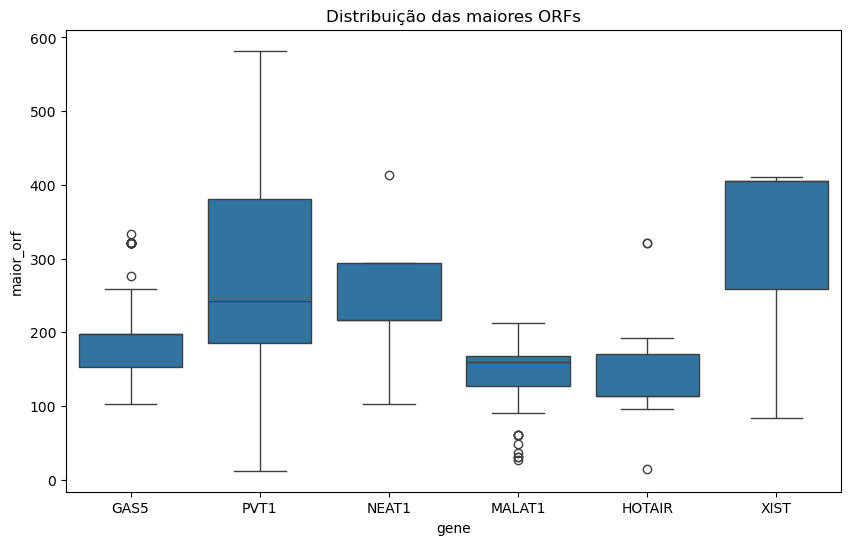

In [22]:
#Fazendo um boxplot para visualizar a distribuição do tamanho do maior ORF por gene
plt.figure(figsize=(10,6))

sns.boxplot(
    data=orf_df,
    x="gene",
    y="maior_orf"
)

plt.title("Distribuição das maiores ORFs")
plt.show()

PVT1 continua aparecendo em toda análise
Até agora PVT1 acumula:
✅ maior número de isoformas
✅ GC elevado
✅ maior ORF observada
✅ enorme diversidade transcricional

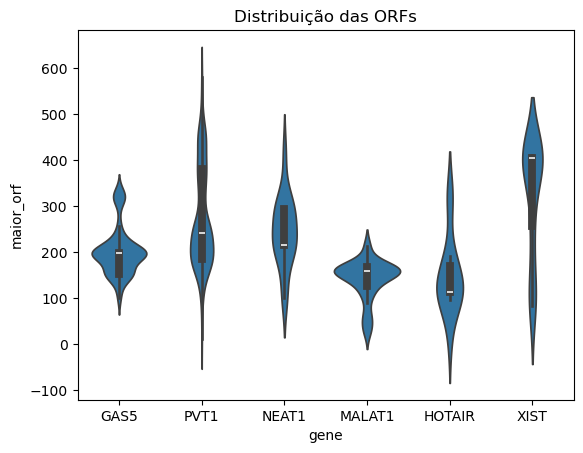

In [23]:
#plots de violino para visualizar a distribuição do tamanho do maior ORF por gene e visualizar o efeito de outliers
sns.violinplot(
    data=orf_df,
    x="gene",
    y="maior_orf"
)

plt.title("Distribuição das ORFs")
plt.show()

<Axes: xlabel='gc', ylabel='maior_orf'>

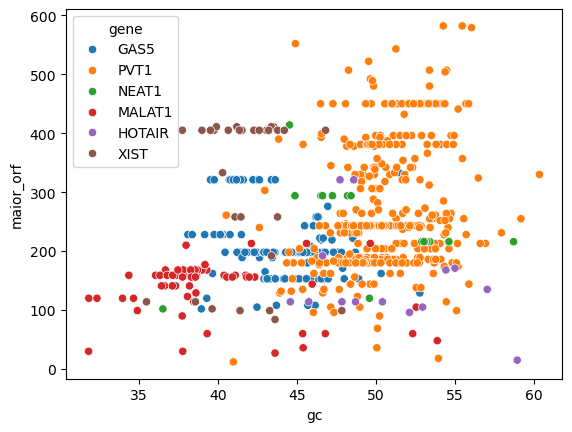

In [24]:
#Sera que transcritos com maior GC tendem a possuir ORFs maiores?
sns.scatterplot(
    data=orf_df.merge(
        gc_df,
        on=["gene","transcrito"]
    ),
    x="gc",
    y="maior_orf",
    hue="gene"
)


GC sozinho não parece explicar a variabilidade das ORFs em PVT1. Logo, arquitetura transcricional de PVT1 pode ser muito mais determinada por eventos de splicing, estrutura gênica e evolução dos transcritos do que simplesmente pela composição de bases.

In [25]:
#analise de dinucleotídeos
dinuc_df = pd.read_csv(
    "/home/shgtz/linfoma_lncRNA/resultados/dinucleotideos.csv"
)

dinuc_df.head()

,gene,transcrito,AA,AC,AG,AT,CA,CC,CG,CT,GA,GC,GG,GT,TA,TC,TG,TT
0,GAS5,GAS5-292,0.071839,0.051724,0.083333,0.050287,0.076149,0.057471,0.011494,0.083333,0.070402,0.061782,0.066092,0.061782,0.038793,0.057471,0.099138,0.058908
1,GAS5,GAS5-231,0.068224,0.049533,0.068224,0.061682,0.072897,0.062617,0.009346,0.076636,0.052336,0.054206,0.057944,0.064486,0.054206,0.055140,0.093458,0.099065
2,GAS5,GAS5-293,0.067568,0.051351,0.079730,0.055405,0.067568,0.052703,0.009459,0.081081,0.063514,0.056757,0.064865,0.066216,0.056757,0.050000,0.097297,0.079730
3,GAS5,GAS5-280,0.068564,0.051746,0.081501,0.054334,0.065977,0.053040,0.009056,0.080207,0.064683,0.054334,0.064683,0.067270,0.058215,0.049159,0.095731,0.081501
4,GAS5,GAS5-255,0.089918,0.050409,0.088556,0.055858,0.077657,0.042234,0.006812,0.077657,0.064033,0.058583,0.055858,0.061308,0.054496,0.053134,0.087193,0.076294


In [26]:
#agrupar por gene
perfil_dinuc = (
    dinuc_df
    .drop(columns=["transcrito"])
    .groupby("gene")
    .mean()
)

perfil_dinuc

,AA,AC,AG,AT,CA,CC,CG,CT,GA,GC,GG,GT,TA,TC,TG,TT
gene,,,,,,,,,,,,,,,,
GAS5,0.084713,0.049154,0.084159,0.057384,0.070680,0.045054,0.007279,0.077970,0.069578,0.055805,0.060073,0.059710,0.051589,0.050206,0.093534,0.083113
HOTAIR,0.083812,0.050304,0.102582,0.046416,0.065979,0.070678,0.032009,0.057846,0.087767,0.062806,0.085654,0.045284,0.045771,0.042420,0.061241,0.059430
MALAT1,0.127558,0.038384,0.094061,0.067585,0.053325,0.031083,0.015683,0.054437,0.080687,0.046952,0.059236,0.052173,0.066168,0.038178,0.069851,0.104641
NEAT1,0.063331,0.035881,0.080965,0.051203,0.052962,0.052691,0.022049,0.068665,0.071565,0.060864,0.103392,0.062872,0.043866,0.046808,0.092149,0.090737
PVT1,0.061263,0.055208,0.069527,0.053759,0.068811,0.077666,0.022815,0.084926,0.074979,0.061226,0.072626,0.043901,0.035165,0.060026,0.087404,0.070696
XIST,0.080177,0.047007,0.069658,0.068082,0.065826,0.057987,0.006923,0.088072,0.061211,0.041839,0.043419,0.052988,0.057558,0.071985,0.079320,0.107947


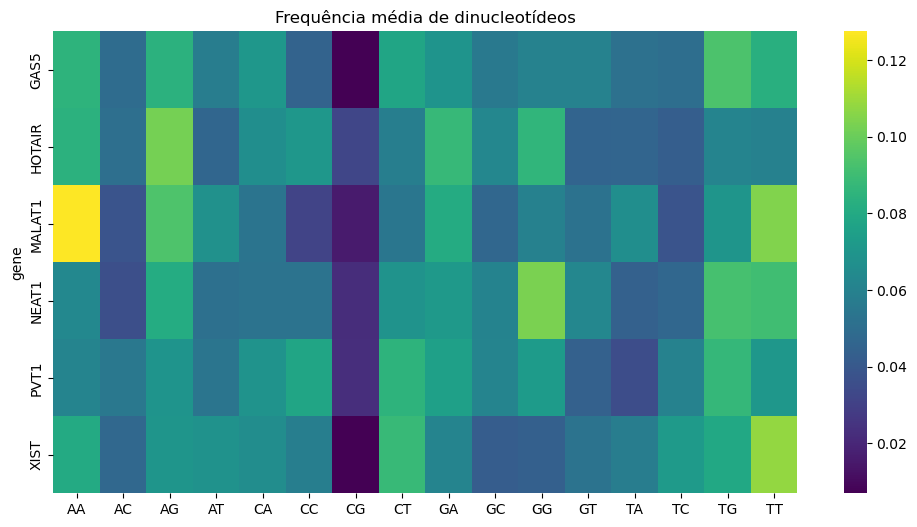

In [27]:
#construindo o heatmap
plt.figure(figsize=(12,6))

sns.heatmap(
    perfil_dinuc,
    cmap="viridis"
)

plt.title(
    "Frequência média de dinucleotídeos"
)

plt.show()

A coluna CG está escura em praticamente todas as linhas.
Isso é esperado biologicamente. Em mamíferos, dinucleotídeos CpG costumam ser sub-representados no genoma devido à metilação de citosinas e posterior desaminação ao longo da evolução.É uma assinatura quase global do genoma humano por tanto não pode ser usada para distinguir nada aqui.É uma assinatura quase global do genoma humano. 
AA muito enriquecido;
TT também elevado;
GC relativamente baixo;
CG muito baixo.
Isso conversa surpreendentemente bem com o que já vimos. Começa a surgir a imagem de um RNA longo cuja função talvez dependa mais de arquitetura global e interação com proteínas do que de conteúdo codificante. 
Por outro lado, visualmente falando NEAT1 e PVT1 parecem mais ricos em motivos contendo G. Isso é interessante porque várias RBPs nucleares reconhecem regiões ricas em purinas.
Não é prova de interação com RBPs específicas, mas podemos investigar mais.XIST apareceu como especial em:

✅ comprimento
✅ distribuição de ORFs
✅ agora também composição

XIST é um scaffold gigantesco envolvido em recrutamento de múltiplos complexos proteicos.Vamos nos aprofundar.




In [28]:
import scipy
print(scipy.__version__)

1.15.3


In [29]:
import sys

print(sys.executable)

/home/shgtz/miniconda3/envs/bioinfo/bin/python


In [30]:
import scipy

print(scipy.__version__)

1.15.3


In [31]:
perfil_genes = perfil_dinuc.T.corr()

perfil_genes

gene,GAS5,HOTAIR,MALAT1,NEAT1,PVT1,XIST
gene,,,,,,
GAS5,1.000000,0.585805,0.775809,0.751100,0.725918,0.824341
HOTAIR,0.585805,1.000000,0.585598,0.636599,0.600487,0.260688
MALAT1,0.775809,0.585598,1.000000,0.561812,0.308035,0.669249
NEAT1,0.751100,0.636599,0.561812,1.000000,0.702917,0.523879
PVT1,0.725918,0.600487,0.308035,0.702917,1.000000,0.624747
XIST,0.824341,0.260688,0.669249,0.523879,0.624747,1.000000


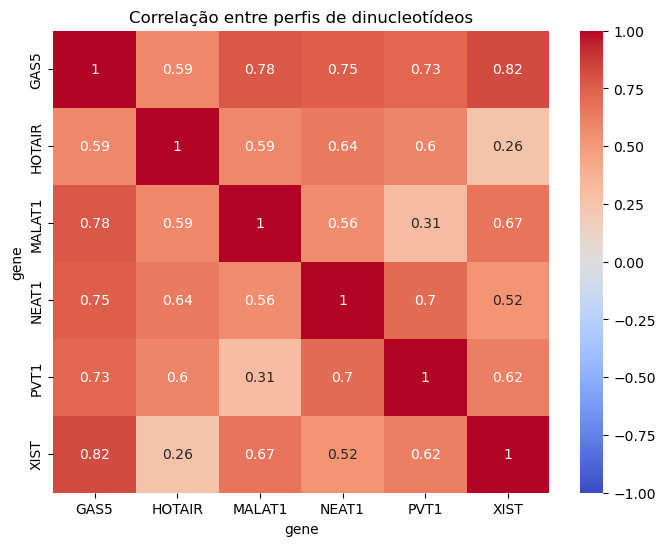

In [32]:
plt.figure(figsize=(8,6))

sns.heatmap(
    perfil_genes,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre perfis de dinucleotídeos")
plt.show()

NEAT1 ↔ PVT1 = 0.70 faz sentido pq pareciam proximos no heatmap anterior (dinucleotídeos). por outro lado as muitas isoformas de pvt1 quando ele é menor que neat1 que tem menos isoformas que ele, sugere splicing (hot spots?) e possivel plasticidade funcional. nao sei vamos ver. Agora:
As diferentes isoformas de PVT1 possuem assinaturas de sequência distintas que sugerem interação com RBPs diferentes?

In [33]:
anotacoes = {
    "MALAT1": "nuclear",
    "NEAT1": "nuclear",
    "XIST": "nuclear",
    "HOTAIR": "nuclear",
    "GAS5": "misto",
    "PVT1": "misto"
}


In [34]:
#ranking de isoformas
pvt1 = df[df["gene"] == "PVT1"]

pvt1.sort_values(
    "tamanho",
    ascending=False
).head(20)

,gene,transcrito,tamanho,biotipo
315,PVT1,PVT1-293,2450,lncRNA
246,PVT1,PVT1-224,2444,lncRNA
402,PVT1,PVT1-216,2255,lncRNA
602,PVT1,PVT1-582,2243,lncRNA
337,PVT1,PVT1-323,2230,lncRNA
541,PVT1,PVT1-283,2187,lncRNA
268,PVT1,PVT1-422,2180,lncRNA
340,PVT1,PVT1-288,2172,lncRNA
347,PVT1,PVT1-435,2168,lncRNA
284,PVT1,PVT1-295,2161,lncRNA


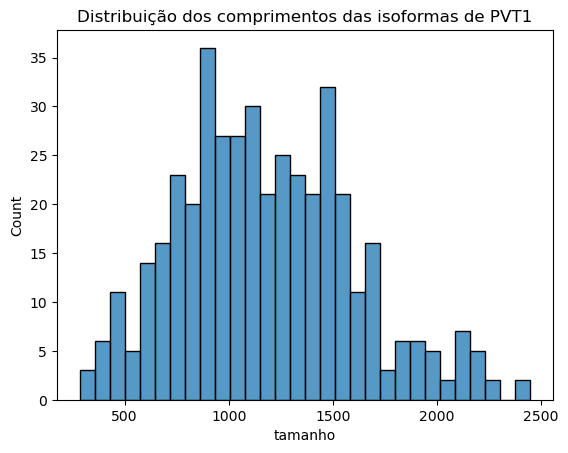

In [35]:
#comprimentos de isoformas de pvt1
sns.histplot(
    pvt1["tamanho"],
    bins=30
)

plt.title("Distribuição dos comprimentos das isoformas de PVT1")
plt.show()

Em linfoma, todas essas isoformas existem simultaneamente ou certos subconjuntos são favorecidos em estados específicos? 

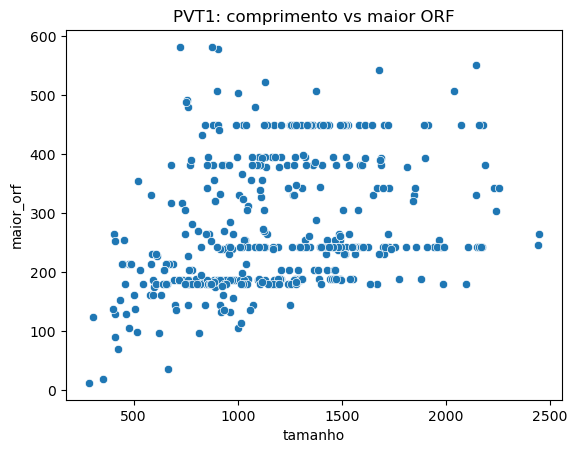

In [36]:
pvt1 = orf_df[
    orf_df["gene"] == "PVT1"
]

sns.scatterplot(
    data=pvt1,
    x="tamanho",
    y="maior_orf"
)

plt.title(
    "PVT1: comprimento vs maior ORF"
)

plt.show()

Hipotese:
PVT1 parece um lncRNA caracterizado mais por plasticidade transcricional do que por tamanho estrutural extremo, o que pode torná-lo especialmente sensível a contexto celular, estado tumoral e regulação por splicing.

In [37]:
#as isoformas de pvt1 maiores possuem orfs maiores?
pvt1["tamanho"].corr(
    pvt1["maior_orf"]
)

np.float64(0.3064389093438999)

isoformas maiores
↓
tendem a ter ORFs maiores?
↓
sim, um pouco mas o comprimento sozinho está longe de explicar o comportamento das ORFs.

Text(0.5, 1.0, 'Distribuição das ORFs em PVT1')

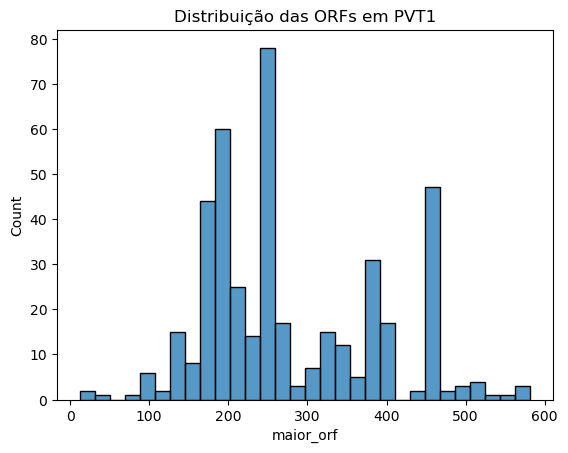

In [38]:
sns.histplot(
    pvt1["maior_orf"],
    bins=30
)

plt.title(
    "Distribuição das ORFs em PVT1"
)

Parece haver uma estrutura mais modular do que a observada nos comprimentos. hipotese: As isoformas de PVT1 podem variar de forma relativamente contínua em comprimento, mas manter conjuntos mais restritos de ORFs.faz sentido biologicamente falando.

In [39]:
pvt1_gc = gc_df[
    gc_df["gene"] == "PVT1"
]

pvt1_orf = orf_df[
    orf_df["gene"] == "PVT1"
]

pvt1_merge = pvt1_gc.merge(
    pvt1_orf,
    on=["gene","transcrito"]
)

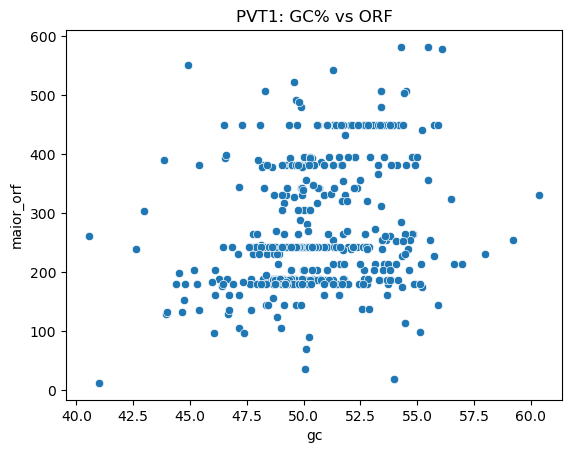

In [40]:
sns.scatterplot(
    data=pvt1_merge,
    x="gc",
    y="maior_orf"
)

plt.title(
    "PVT1: GC% vs ORF"
)

plt.show()

In [41]:
pvt1_merge["gc"].corr(
    pvt1_merge["maior_orf"]
)

np.float64(0.2672480836463837)

PVT1
↓
426 isoformas
↓
não é o mais longo
↓
não tem a maior correlação comprimento-ORF
↓
não tem comportamento explicado por GC
↓
parece altamente plástico

Para estudar splicing de verdade, em algum momento precisaremos também do:
Plain Text
gencode.v47.annotation.gtf
e possivelmente das coordenadas genômicas. mais para frente

Por enquanto, lgumas isoformas de PVT1 estão enriquecidas em motivos sabidamente ligados a RBPs de splicing?

In [42]:
#função para contar motivo
def contar_motivo(seq, motivo):
    return seq.count(motivo)

#motivo reconhecido frequentemente por SR
motivo = "GAAGAA"

As isoformas mais longas acumulam mais desses motivos? Existem isoformas excepcionalmente enriquecidas?

Será que parte dessa enorme diversidade que encontramos computacionalmente reflete uma predisposição do locus PVT1 a gerar moléculas funcionalmente distintas, capazes de atuar em compartimentos diferentes e em processos biológicos diferentes?

Entre as 426 isoformas que você encontrou:
existem grupos de isoformas com enriquecimento diferencial em motivos associados a proteínas reguladoras de splicing?
PVT1 tem muitas isoformas
↓
algumas podem surgir por programas específicos de splicing
↓
esses programas podem estar regulados por RBPs
↓
esses programas podem ter relevância tumoral


Potencial de isoformas
↓
Programa de splicing específico
↓
Produção de certas variantes
↓
Contexto tumoral

A plasticidade funcional de PVT1 pode emergir
da geração diferencial de isoformas mediada
por programas de splicing dependentes de RBPs.

Existem subconjuntos de isoformas de PVT1 enriquecidos em determinados motivos regulatórios?

In [43]:
#testando o ambiente
import sys

print(sys.executable)

/home/shgtz/miniconda3/envs/bioinfo/bin/python


Objeitvo: PVT1
↓
isoformas
↓
motivos potencialmente ligados a RBPs

In [44]:
#importado todo o necessário
from Bio import SeqIO
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [45]:
def contar_motivo(seq, motivo):
    return seq.count(motivo)

In [46]:
motivos = {
    "SRSF1_like":"GAAGAA",
    "PTBP1_like":"TCTCTC",
    "HNRNPC_like":"TTTTT",
    "G_rich":"GGGG",
    "AU_rich":"ATTTAT"
}

In [47]:
#construindo o dataframe com as informações 
pvt1_motivos = []

for registro in SeqIO.parse(
    "/home/shgtz/linfoma_lncRNA/dados_brutos/gencode.v47.transcripts.fa",
    "fasta"
):

    campos = registro.description.split("|")

    gene = campos[5]

    if gene != "PVT1":
        continue

    seq = str(registro.seq)

    linha = {
        "transcrito": campos[4],
        "tamanho": len(seq)
    }

    for nome, motivo in motivos.items():

        linha[nome] = contar_motivo(
            seq,
            motivo
        )

    pvt1_motivos.append(linha)

pvt1_motivos = pd.DataFrame(
    pvt1_motivos
)

pvt1_motivos.head()

,transcrito,tamanho,SRSF1_like,PTBP1_like,HNRNPC_like,G_rich,AU_rich
0,PVT1-310,1176,0,0,2,5,0
1,PVT1-316,891,0,0,0,4,0
2,PVT1-345,988,0,0,0,4,1
3,PVT1-513,451,0,0,0,2,0
4,PVT1-234,1281,0,0,2,5,0


In [48]:
#estatistica ds motivos de pvrt1
pvt1_motivos.describe()

,tamanho,SRSF1_like,PTBP1_like,HNRNPC_like,G_rich,AU_rich
count,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000
mean,1179.640845,0.112676,0.194836,1.605634,3.845070,0.382629
std,422.434385,0.377582,0.487077,1.834151,1.908356,0.629905
min,283.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,888.500000,0.000000,0.000000,0.000000,2.000000,0.000000
50%,1132.500000,0.000000,0.000000,2.000000,4.000000,0.000000
75%,1465.750000,0.000000,0.000000,2.000000,5.000000,1.000000
max,2450.000000,3.000000,3.000000,13.000000,11.000000,3.000000


Isso significa que mais da metade das isoformas:
não contém nosso motivo simplificado para SRSF1;
não contém nosso motivo simplificado para PTBP1;
não contém nosso motivo AU-rich.
Mas quase todas carregam algum grau de:
Plain Text
HNRNPC_like
GGGG (G-rich)

In [49]:
for col in [
    "SRSF1_like",
    "PTBP1_like",
    "HNRNPC_like",
    "G_rich",
    "AU_rich"
]:

    pvt1_motivos[col + "_norm"] = (
        pvt1_motivos[col]
        / pvt1_motivos["tamanho"]
    ) * 1000

In [50]:
#procurar as isoformas mais enriquecidas em possíveis motivos relacionados a splicing.
pvt1_motivos.sort_values(
    "SRSF1_like_norm",
    ascending=False
).head(20)

,transcrito,tamanho,SRSF1_like,PTBP1_like,HNRNPC_like,G_rich,AU_rich,SRSF1_like_norm,PTBP1_like_norm,HNRNPC_like_norm,G_rich_norm,AU_rich_norm
298,PVT1-589,423,1,0,0,1,0,2.364066,0.000000,0.000000,2.364066,0.000000
299,PVT1-590,479,1,0,0,1,0,2.087683,0.000000,0.000000,2.087683,0.000000
424,PVT1-221,1020,2,0,7,3,0,1.960784,0.000000,6.862745,2.941176,0.000000
368,PVT1-320,1114,2,1,2,1,2,1.795332,0.897666,1.795332,0.897666,1.795332
119,PVT1-347,2143,3,0,4,6,1,1.399907,0.000000,1.866542,2.799813,0.466636
249,PVT1-471,1541,2,3,2,5,1,1.297859,1.946788,1.297859,3.244646,0.648929
238,PVT1-210,1578,2,3,0,5,1,1.267427,1.901141,0.000000,3.168568,0.633714
164,PVT1-248,935,1,0,1,1,1,1.069519,0.000000,1.069519,1.069519,1.069519
420,PVT1-325,964,1,0,2,2,0,1.037344,0.000000,2.074689,2.074689,0.000000
14,PVT1-501,2073,2,0,1,5,0,0.964785,0.000000,0.482393,2.411963,0.000000


In [51]:
pvt1_motivos.sort_values(
    "PTBP1_like_norm",
    ascending=False
).head(20)

,transcrito,tamanho,SRSF1_like,PTBP1_like,HNRNPC_like,G_rich,AU_rich,SRSF1_like_norm,PTBP1_like_norm,HNRNPC_like_norm,G_rich_norm,AU_rich_norm
386,PVT1-272,609,0,2,3,2,0,0.000000,3.284072,4.926108,3.284072,0.000000
380,PVT1-313,661,0,2,3,2,0,0.000000,3.025719,4.538578,3.025719,0.000000
383,PVT1-296,751,0,2,3,2,0,0.000000,2.663116,3.994674,2.663116,0.000000
382,PVT1-299,755,0,2,3,2,0,0.000000,2.649007,3.973510,2.649007,0.000000
384,PVT1-222,777,0,2,3,2,0,0.000000,2.574003,3.861004,2.574003,0.000000
385,PVT1-230,821,0,2,3,2,0,0.000000,2.436054,3.654080,2.436054,0.000000
381,PVT1-297,854,0,2,3,2,0,0.000000,2.341920,3.512881,2.341920,0.000000
312,PVT1-505,932,0,2,2,1,0,0.000000,2.145923,2.145923,1.072961,0.000000
305,PVT1-604,475,0,1,0,0,0,0.000000,2.105263,0.000000,0.000000,0.000000
310,PVT1-606,506,0,1,0,1,0,0.000000,1.976285,0.000000,1.976285,0.000000


Todos eles têm tamanhos parecidos.
Entre:
Plain Text
600 e 800 nt
aproximadamente.
Isso pode ser coincidência.
Mas também pode indicar um subconjunto estruturalmente semelhante dentro do universo PVT1.

In [52]:
#heatmap para ver a distribuição dessas assinaturas
colunas = [
    "SRSF1_like_norm",
    "PTBP1_like_norm",
    "HNRNPC_like_norm",
    "G_rich_norm",
    "AU_rich_norm"
]

top = pvt1_motivos[
    colunas + ["transcrito"]
].copy()

top = top.set_index(
    "transcrito"
)


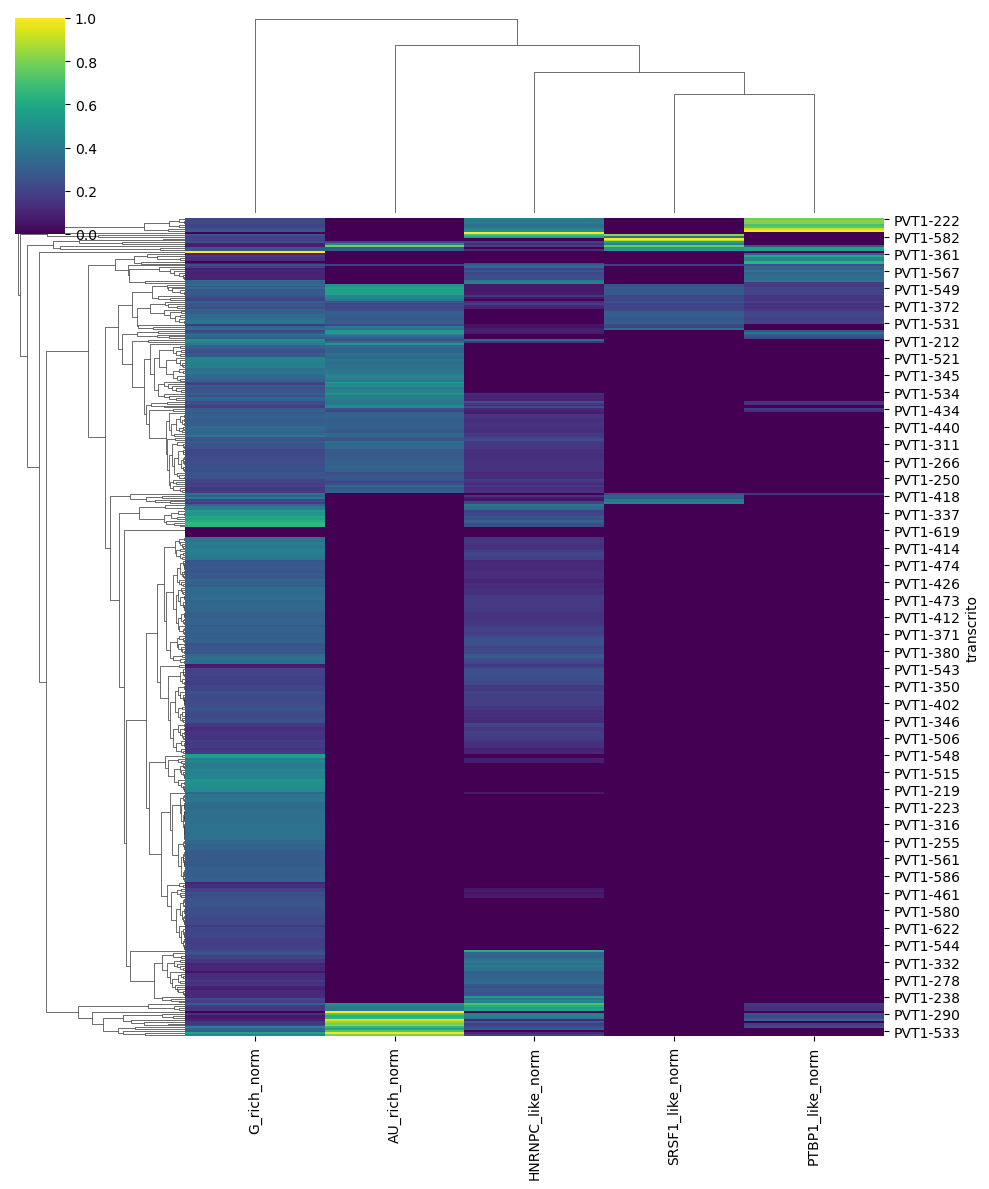

In [53]:
sns.clustermap(
    top[colunas],
    cmap="viridis",
    standard_scale=1,
    figsize=(10,12)
)

Parece haver dois grandes blocos:

HNRNPC_like
G_rich de um lado
e 
SRSF1_like
PTBP1_like
AU_rich do outro

Parecem haver dois grupos: transcritos com enriquecimento forte em HNRNPC_like e G-rich, outro grupo enriquecido em PTBP1_like e pobre no restante e uma massa centra com G_rich moderado + HNRNPC_like moderado e poucos sinais dos demais motivos. isso conversa bem com a literatura pqsegundo a informação extraída do leapspace:
PVT1
↓
não possui um hotspot único
↓
possui múltiplas variantes funcionais
↓
plasticidade dependente de splicing

Qual conjunto de proteínas poderia ter afinidade por essa isoforma?
Quero saber quantas isoformas estão em cada "família".


In [55]:
#importar
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [56]:
#selecionar as variáveis úteis
features = [
    "SRSF1_like_norm",
    "PTBP1_like_norm",
    "HNRNPC_like_norm",
    "G_rich_norm",
    "AU_rich_norm"
]

In [57]:
#padronizar
X = StandardScaler().fit_transform(
    pvt1_motivos[features]
)


In [58]:
#executar o pca
pca = PCA(n_components=2)

coords = pca.fit_transform(X)

In [59]:
#verificar a informação que foi capturada
print(
    pca.explained_variance_ratio_
)

[0.29688244 0.23761775]


Mais da metade da diversidade observada nas assinaturas de motivos de PVT1 pode ser visualizada em apenas duas dimensões.

In [60]:
pca_df = pd.DataFrame({
    "PC1": coords[:,0],
    "PC2": coords[:,1],
    "transcrito": pvt1_motivos["transcrito"]
})

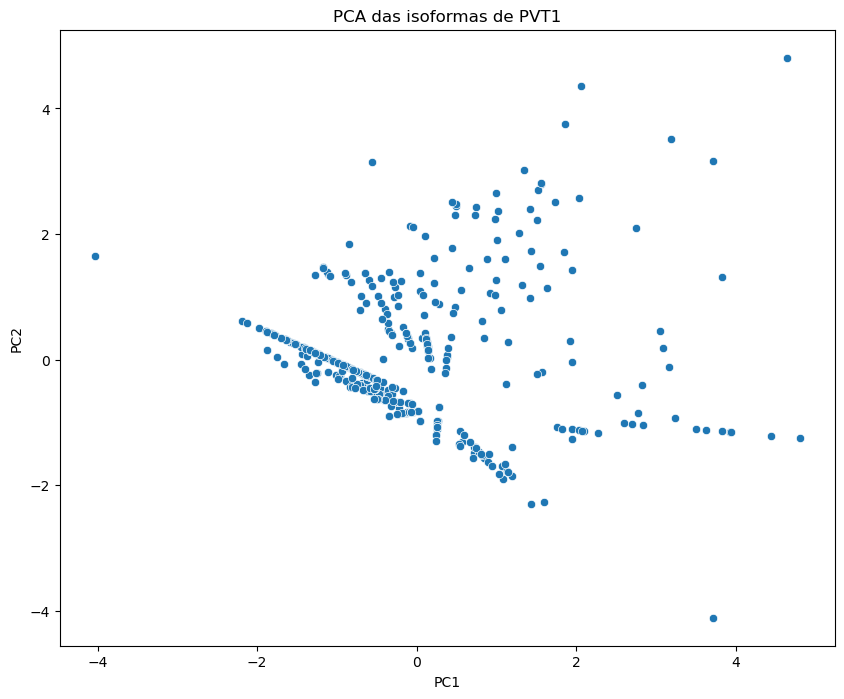

In [61]:
plt.figure(figsize=(10,8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2"
)

plt.title(
    "PCA das isoformas de PVT1"
)

plt.show()

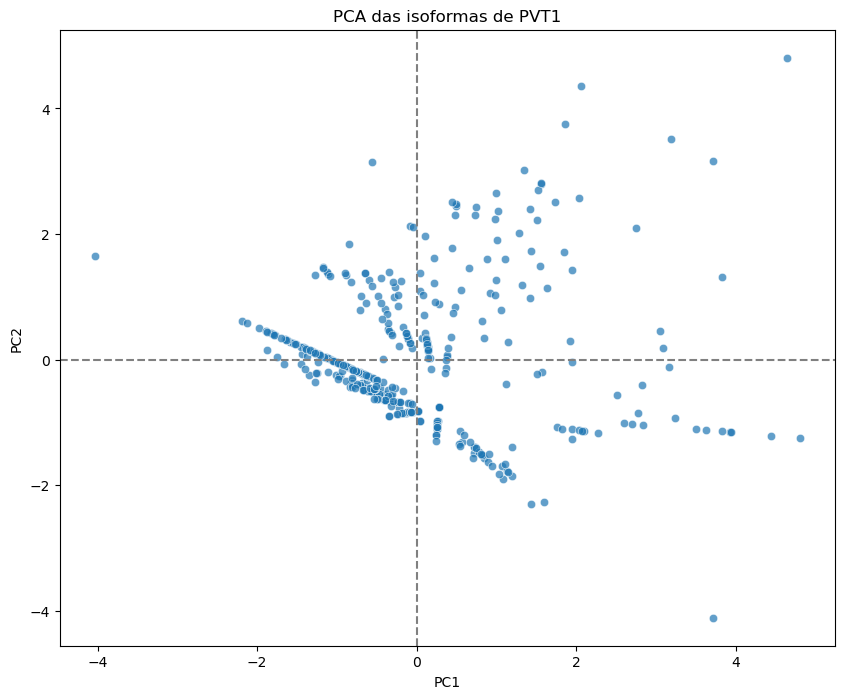

In [62]:
plt.figure(figsize=(10,8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    alpha=0.7
)

plt.axhline(
    0,
    color="gray",
    linestyle="--"
)

plt.axvline(
    0,
    color="gray",
    linestyle="--"
)

plt.title(
    "PCA das isoformas de PVT1"
)

plt.show()

Um sistema com múltiplas assinaturas combinatórias do que uma população única. Precisamos entender:
O que significa biologicamente PC1? O que significa biologicamente PC2?

In [63]:
#ver a tabela
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1","PC2"],
    index=features
)

loadings

,PC1,PC2
SRSF1_like_norm,0.319186,0.558861
PTBP1_like_norm,0.576924,0.078428
HNRNPC_like_norm,0.485573,-0.474126
G_rich_norm,-0.515137,0.287800
AU_rich_norm,0.253243,0.611474


In [64]:
#identificando os outliers(transcritos mais estranhos do conjunto)
pca_df["distancia"] = (
    pca_df["PC1"]**2 +
    pca_df["PC2"]**2
) ** 0.5

pca_df.sort_values(
    "distancia",
    ascending=False
).head(20)

,PC1,PC2,transcrito,distancia
368,4.651308,4.808172,PVT1-320,6.689782
300,3.713168,-4.112471,PVT1-593,5.540761
386,4.803284,-1.252839,PVT1-272,4.963984
249,3.717765,3.161888,PVT1-471,4.880503
298,2.065785,4.357215,PVT1-589,4.822115
238,3.188572,3.507934,PVT1-210,4.740527
380,4.447237,-1.213886,PVT1-313,4.609928
406,-4.032921,1.650422,PVT1-353,4.357562
299,1.856702,3.759231,PVT1-590,4.192751
383,3.947520,-1.159215,PVT1-296,4.114207


PCA1 esta separando PTBP1_like
+
HNRNPC_like
vs. G-Rich ou seja, PC1 parece representar diferentes "estratégias composicionais" potencialmente relacionadas a diferentes conjuntos de RBPs. PCA2 esta sendo puxado por SRSF1_like
+
AU_rich. Como bs importante vemos que o pvt1 272 se repite como candidato interessante

Minha hipotese inicial: PVT1
↓
muitas isoformas
↓
splicing
↓
plasticidade
O que o PCA esta sugerindo:
PVT1
↓
muitas isoformas
↓
algumas delas possuem assinaturas composicionais muito distintas
↓
possivelmente diferentes programas regulatórios


In [65]:
#os dez transcritos mais distantes
top10 = (
    pca_df
    .sort_values(
        "distancia",
        ascending=False
    )
    .head(10)
)

top10

,PC1,PC2,transcrito,distancia
368,4.651308,4.808172,PVT1-320,6.689782
300,3.713168,-4.112471,PVT1-593,5.540761
386,4.803284,-1.252839,PVT1-272,4.963984
249,3.717765,3.161888,PVT1-471,4.880503
298,2.065785,4.357215,PVT1-589,4.822115
238,3.188572,3.507934,PVT1-210,4.740527
380,4.447237,-1.213886,PVT1-313,4.609928
406,-4.032921,1.650422,PVT1-353,4.357562
299,1.856702,3.759231,PVT1-590,4.192751
383,3.947520,-1.159215,PVT1-296,4.114207


In [66]:
top10["transcrito"]

368    PVT1-320
300    PVT1-593
386    PVT1-272
249    PVT1-471
298    PVT1-589
238    PVT1-210
380    PVT1-313
406    PVT1-353
299    PVT1-590
383    PVT1-296
Name: transcrito, dtype: object

In [68]:
#cruzando com pvt1 motivos
top10_detalhes = (
    top10.merge(
        pvt1_motivos,
        on="transcrito"
    )
)

top10_detalhes

,PC1,PC2,transcrito,distancia,tamanho,SRSF1_like,PTBP1_like,HNRNPC_like,G_rich,AU_rich,SRSF1_like_norm,PTBP1_like_norm,HNRNPC_like_norm,G_rich_norm,AU_rich_norm
0,4.651308,4.808172,PVT1-320,6.689782,1114,2,1,2,1,2,1.795332,0.897666,1.795332,0.897666,1.795332
1,3.713168,-4.112471,PVT1-593,5.540761,412,0,0,4,0,0,0.000000,0.000000,9.708738,0.000000,0.000000
2,4.803284,-1.252839,PVT1-272,4.963984,609,0,2,3,2,0,0.000000,3.284072,4.926108,3.284072,0.000000
3,3.717765,3.161888,PVT1-471,4.880503,1541,2,3,2,5,1,1.297859,1.946788,1.297859,3.244646,0.648929
4,2.065785,4.357215,PVT1-589,4.822115,423,1,0,0,1,0,2.364066,0.000000,0.000000,2.364066,0.000000
5,3.188572,3.507934,PVT1-210,4.740527,1578,2,3,0,5,1,1.267427,1.901141,0.000000,3.168568,0.633714
6,4.447237,-1.213886,PVT1-313,4.609928,661,0,2,3,2,0,0.000000,3.025719,4.538578,3.025719,0.000000
7,-4.032921,1.650422,PVT1-353,4.357562,590,0,0,0,7,0,0.000000,0.000000,0.000000,11.864407,0.000000
8,1.856702,3.759231,PVT1-590,4.192751,479,1,0,0,1,0,2.087683,0.000000,0.000000,2.087683,0.000000
9,3.947520,-1.159215,PVT1-296,4.114207,751,0,2,3,2,0,0.000000,2.663116,3.994674,2.663116,0.000000


Os transcritos mais distantes: Eles não são os maiores transcritos.
Eles não são necessariamente os mais ricos em ORFs.
Eles não são necessariamente os mais ricos em GC.
Eles são os mais "diferentes" quando analisamos simultaneamente:
SRSF1_like
PTBP1_like
HNRNPC_like
G_rich
AU_rich.
O grupo Grupo PVT1-272 / PVT1-313 / PVT1-296 sao irmaos de PTBP1_like elevado
HNRNPC_like elevado
G_rich moderado
e tem SRSF1_like = 0
Isso sugere um padrão regulatório compartilhado.
PVT1-593 ficou isolado HNRNPC_like_norm = 9.7 que é enorme e sugere uma assinatura. O PVT1-353 tem G_rich_norm = 11.86 e praticamente zero para o resto, parece uma entidade.
Muuiito interessante PVT1-320 ele acumula simultaneamente:SRSF1_like
PTBP1_like
HNRNPC_like
AU_rich


Hipotese inicial:
PVT1
↓
426 isoformas
↓
splicing
↓
plasticidade

refinamento:
PVT1
↓
426 isoformas
↓
subconjuntos com assinaturas composicionais distintas
↓
possivelmente diferentes programas de interação com RBPs

Por tanto:
Isoformas de PVT1 apresentam assinaturas distintas de motivos potencialmente associados a proteínas reguladoras de RNA, sugerindo que a diversidade transcricional do locus pode refletir múltiplos programas regulatórios em vez de uma única entidade funcional.

Pergunta:
Os transcritos:PVT1-320
PVT1-272
PVT1-313
PVT1-593
PVT1-353 de onde procedem estruturalmente? talvez compartilhem carateristicas e estruturas.

Agora:
✅ baixar a anotação GTF do GENCODE
✅ localizar esses transcritos dentro do gene PVT1
✅ descobrir quais exons aparecem nos outliers

Como identificmos aqueles "estranhos" vale a pensa saber se:
Essas isoformas compartilham exons específicos?
Ou:
Existem exons associados às assinaturas que observamos?